## Seminar 2. Zero-shot with CLIP and CLAP

In this notebook we use text descriptions to classify images with CLIP and sounds with CLAP. Then we generate answers with Qwen-VL and compare sequential and batched inference with vLLM.

We will cover:

- Image-text similarity and zero-shot classification with CLIP.
- Prompt templates and ensembles on CIFAR-100.
- Candidate lists, softmax scores, and image crops.
- Audio classification with CLAP.
- Image understanding with Qwen-VL.
- Batched inference with vLLM.

CLIP and CLAP can run on CPU. The Qwen-VL and vLLM sections need a CUDA GPU.

> Here, *zero-shot* means using pretrained weights without fitting them to this task.

In [ ]:
%pip -q install "vllm==0.11.0; sys_platform == 'linux'" "transformers==4.57.6" "datasets==4.5.0" "accelerate==1.10.1" "huggingface_hub<1" scikit-image matplotlib seaborn pandas pillow requests scipy soundfile

In [ ]:
import gc
import io
import math
import os
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch
import torch.nn.functional as F
from datasets import load_dataset
from IPython.display import Audio, HTML, display
from PIL import Image, ImageDraw
from skimage import data
from transformers import CLIPModel, CLIPProcessor

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


COLOR = "#4F8A3D"
LIGHT_COLOR = "#BDD8AC"
CMAP = "Greens"
sns.set_theme(style="whitegrid", palette=[COLOR, LIGHT_COLOR], context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.alpha": 0.25,
})

print("Device:", device)
print("PyTorch:", torch.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU runtime.")

Device: cuda
PyTorch: 2.8.0+cu128
GPU: NVIDIA A100-SXM4-40GB


### Images and descriptions

We start with six images from different domains: photographs, a silhouette and a microscopy image. Each image is paired with a short description.

Images we took from here: [scikit-image sample collection](https://scikit-image.org/docs/stable/api/skimage.data.html).

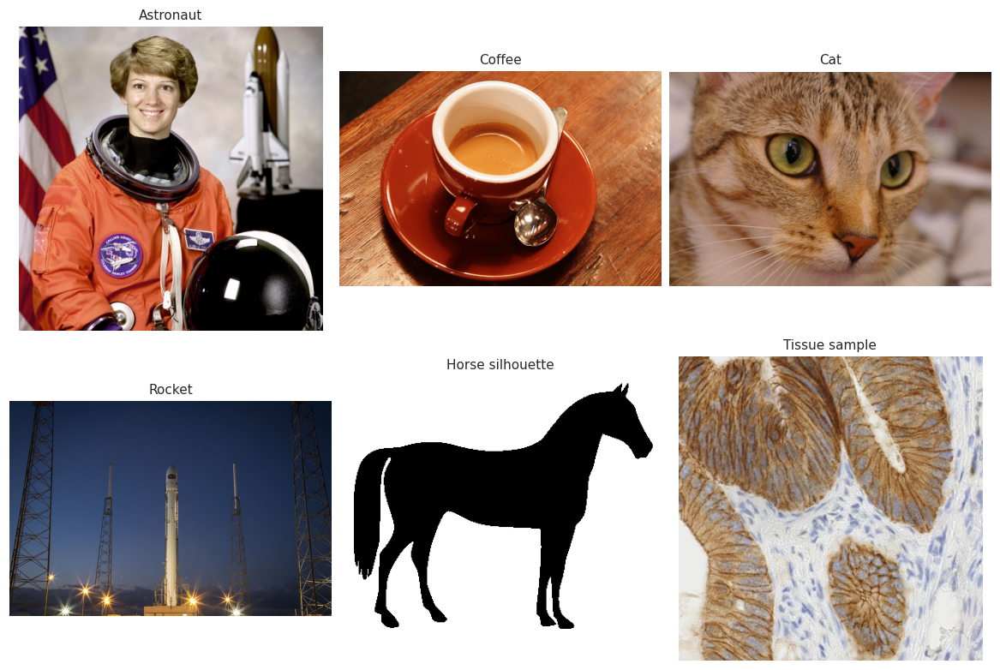

In [ ]:
gallery_images = [
    Image.fromarray(data.astronaut()).convert("RGB"),
    Image.fromarray(data.coffee()).convert("RGB"),
    Image.fromarray(data.chelsea()).convert("RGB"),
    Image.fromarray(data.rocket()).convert("RGB"),
    Image.fromarray((data.horse() * 255).astype("uint8")).convert("RGB"),
    Image.fromarray(data.immunohistochemistry()).convert("RGB"),
]
gallery_names = ["Astronaut", "Coffee", "Cat", "Rocket", "Horse silhouette", "Tissue sample"]
gallery_captions = [
    "a portrait of an astronaut in a spacesuit",
    "a cup of coffee on a wooden table",
    "a close-up photo of a tabby cat",
    "a rocket on a launch pad",
    "a black and white silhouette of a horse",
    "a microscope image of stained biological tissue",
]

# lets display images
def show_gallery(images, titles, ncols=3, size=3.5):
    nrows = math.ceil(len(images) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size),
                             squeeze=False, layout="constrained")
    for ax in axes.flat:
        ax.axis("off")
    for ax, image, title in zip(axes.flat, images, titles):
        ax.imshow(image)
        title = "\n".join(textwrap.fill(line, 34) for line in title.splitlines())
        ax.set_title(title, fontsize=10)
    plt.show()

show_gallery(gallery_images, gallery_names)

### CLIP as a zero-shot classifier

[CLIP](https://proceedings.mlr.press/v139/radford21a.html) encodes images and text into a shared space. For an image $x$ and candidate description $t_c$, we compute cosine similarity and select the highest score:

$$s_c = \frac{f_I(x)^\top f_T(t_c)}{\|f_I(x)\|\,\|f_T(t_c)\|}, \qquad \hat{c}=\arg\max_c s_c.$$


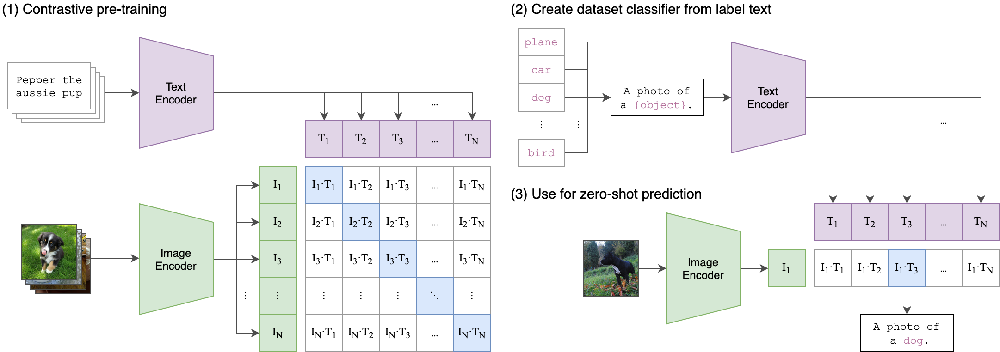

In [ ]:
CLIP_ID = "openai/clip-vit-base-patch32"
clip_processor = CLIPProcessor.from_pretrained(CLIP_ID)
clip_model = CLIPModel.from_pretrained(CLIP_ID).to(device).eval()
clip_scale = clip_model.logit_scale.exp().item()

@torch.inference_mode()
def encode_images(images, batch_size=32):
    features = []
    for start in range(0, len(images), batch_size):
        # resize, center-crop and normalize each image for clip
        batch = images[start:start + batch_size]
        inputs = clip_processor(images=batch, return_tensors="pt").to(device)
        vectors = clip_model.get_image_features(**inputs)  # [batch, 512]

        # l2 normalization makes a dot product equal to cosine similarity
        features.append(F.normalize(vectors.float(), dim=-1).cpu())
    return torch.cat(features)

@torch.inference_mode()
def encode_texts(texts, batch_size=128):
    features = []
    for start in range(0, len(texts), batch_size):
        # tokenize descriptions and pad them to the same length
        batch = texts[start:start + batch_size]
        inputs = clip_processor(text=batch, padding=True, truncation=True,
                                return_tensors="pt").to(device)
        vectors = clip_model.get_text_features(**inputs)  # [batch, 512]
        features.append(F.normalize(vectors.float(), dim=-1).cpu())
    return torch.cat(features)

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

In [ ]:
gallery_features = encode_images(gallery_images)
caption_features = encode_texts(gallery_captions)

# [6 images, 512] @ [512, 6 descriptions] -> [6, 6]
gallery_similarity = gallery_features @ caption_features.T
print("Image features:", tuple(gallery_features.shape))
print("Text features:", tuple(caption_features.shape))

Image features: (6, 512)
Text features: (6, 512)


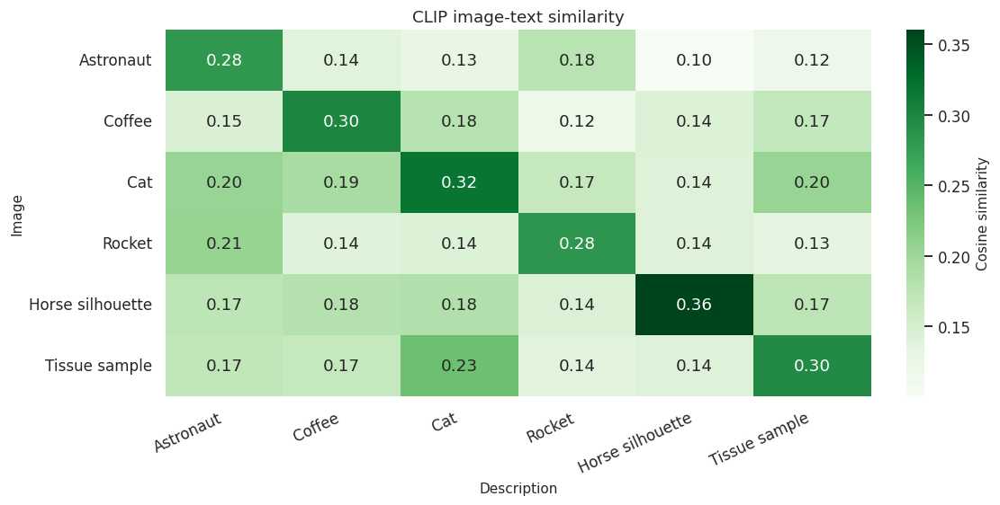

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
sns.heatmap(gallery_similarity.numpy(), annot=True, fmt=".2f", cmap=CMAP,
            xticklabels=gallery_names, yticklabels=gallery_names,
            cbar_kws={"label": "Cosine similarity"}, ax=ax)
ax.set(xlabel="Description", ylabel="Image", title="CLIP image-text similarity")
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
plt.show()

Every image has its highest similarity with the matching description.

### From six examples to 100 classes

We use 200 images from the **CIFAR-100 test split** ([dataset on Hugging Face](https://huggingface.co/datasets/uoft-cs/cifar100)) to select a prompt and a separate 500 to evaluate it. Although the weights stay fixed, development labels guide prompt selection, so the evaluation images must remain separate.

CIFAR-100 images are only $32\times32$ pixels. Enlarging them adds no detail.

README.md: 0.00B [00:00, ?B/s]

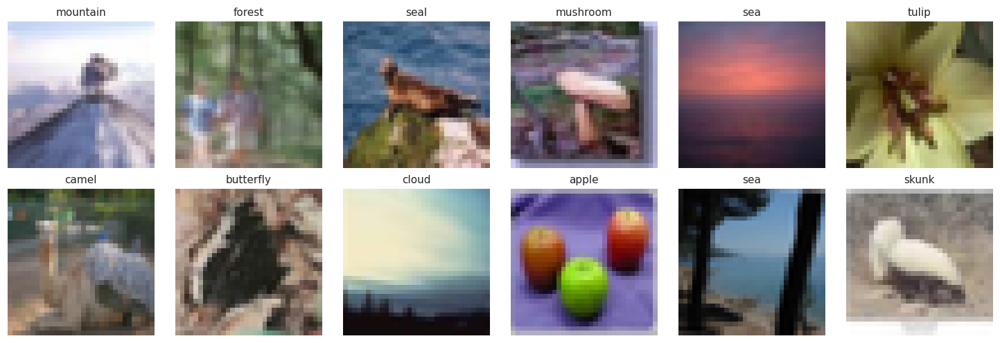

In [ ]:
N_DEV, N_TEST = 200, 500
cifar = load_dataset("uoft-cs/cifar100", split="test", streaming=True)
class_names = cifar.features["fine_label"].names

# fix the truncated "crab" label
class_names = ["crab" if name == "cra" else name.replace("_", " ") for name in class_names]
examples = list(cifar.take(N_DEV + N_TEST))
assert len(examples) == N_DEV + N_TEST

cifar_images = [example["img"].convert("RGB") for example in examples]
cifar_targets = torch.tensor([example["fine_label"] for example in examples])
show_gallery(cifar_images[:12], [class_names[i] for i in cifar_targets[:12]], ncols=6, size=2.2)

In [ ]:
# image embeddings are reused
cifar_features = encode_images(cifar_images)

# we use separate images for prompt selection and evaluation
dev_features, test_features = cifar_features[:N_DEV], cifar_features[N_DEV:]
dev_targets, test_targets = cifar_targets[:N_DEV], cifar_targets[N_DEV:]
test_images = cifar_images[N_DEV:]
print(f"Development: {len(dev_targets)} images, held-out evaluation: {len(test_targets)} images")

Development: 200 images, held-out evaluation: 500 images


#### Prompt templates

Lets compare class names, two templates and an ensemble of three templates. For each class, the ensemble averages the normalized text embeddings and normalizes the result again.

In [ ]:
prompt_sets = {
    "Class name": ["{}"],
    "Photo": ["a photo of a {}."],
    "Blurry photo": ["a blurry photo of a {}."],
    "Ensemble": ["a photo of a {}.", "a blurry photo of a {}.", "a close-up photo of a {}."],
}
class_vectors = {}
dev_rows = []

for name, templates in prompt_sets.items():
    template_vectors = []
    for template in templates:
        descriptions = [template.format(label) for label in class_names]
        template_vectors.append(encode_texts(descriptions))

    # [templates, 100 classes, 512] -> one vector per class
    vectors = torch.stack(template_vectors).mean(dim=0)
    class_vectors[name] = F.normalize(vectors, dim=-1)

    scores = dev_features @ class_vectors[name].T
    predictions = scores.argmax(dim=-1)
    accuracy = (predictions == dev_targets).float().mean().item()
    dev_rows.append({"Prompt": name, "Development accuracy": accuracy})

dev_results = pd.DataFrame(dev_rows)
selected_prompt = dev_results.loc[dev_results["Development accuracy"].idxmax(), "Prompt"]
display(dev_results.style.format({"Development accuracy": "{:.1%}"}))

,Prompt,Development accuracy
0,Class name,65.0%
1,Photo,69.5%
2,Blurry photo,68.5%
3,Ensemble,72.0%


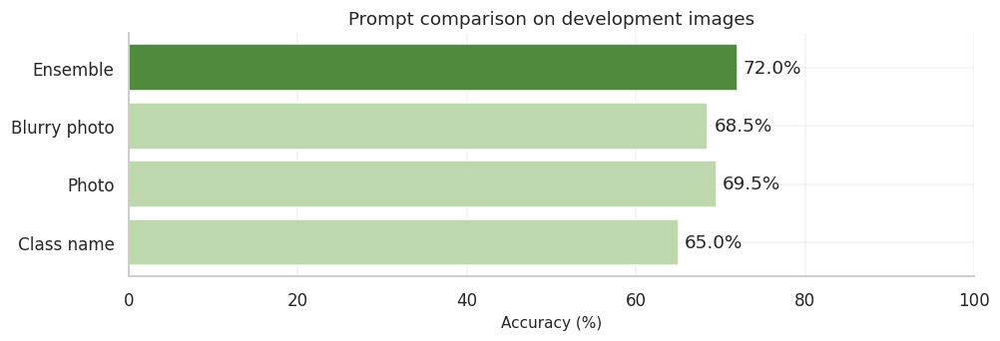

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
colors = [COLOR if name == selected_prompt else LIGHT_COLOR for name in dev_results["Prompt"]]
bars = ax.barh(dev_results["Prompt"], 100 * dev_results["Development accuracy"], color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set(xlabel="Accuracy (%)", xlim=(0, 100), title="Prompt comparison on development images")
plt.show()

The ensemble gives the highest development accuracy: 72.0%, compared with 65.0% for class names.

In [ ]:
baseline_scores = test_features @ class_vectors["Class name"].T
test_scores = test_features @ class_vectors[selected_prompt].T
baseline_pred = baseline_scores.argmax(dim=-1)
test_pred = test_scores.argmax(dim=-1)

evaluation_rows = [{"Method": "Uniform random (expected)", "Top-1": 0.01, "Top-5": 0.05}]
for name, scores in [("Class name", baseline_scores), (selected_prompt, test_scores)]:
    # top-5 is correct if the true class appears anywhere in the five best scores
    top5 = scores.topk(5, dim=-1).indices
    evaluation_rows.append({
        "Method": name,
        "Top-1": (scores.argmax(-1) == test_targets).float().mean().item(),
        "Top-5": (top5 == test_targets[:, None]).any(dim=-1).float().mean().item(),
    })
evaluation = pd.DataFrame(evaluation_rows)
display(evaluation.style.format({"Top-1": "{:.1%}", "Top-5": "{:.1%}"}))

,Method,Top-1,Top-5
0,Uniform random (expected),1.0%,5.0%
1,Class name,59.0%,85.6%
2,Ensemble,63.6%,88.2%


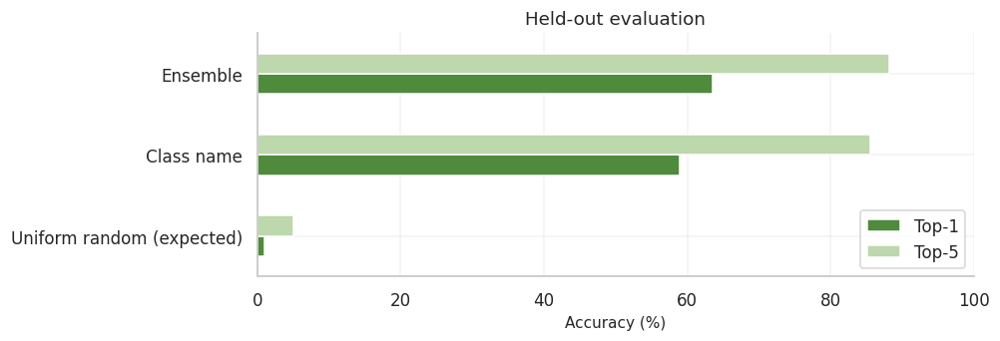

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
evaluation.set_index("Method").mul(100).plot.barh(ax=ax, color=[COLOR, LIGHT_COLOR])
ax.set(xlabel="Accuracy (%)", ylabel="", xlim=(0, 100), title="Held-out evaluation")
ax.legend(title="")
plt.show()

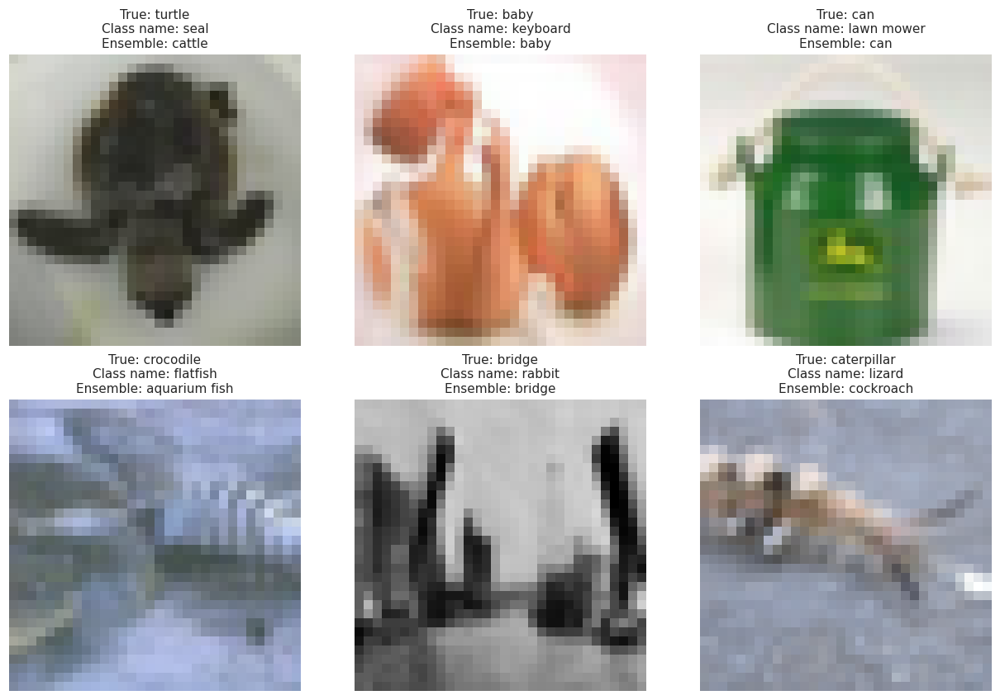

In [ ]:
# the first six images whose predictions changed with the selected prompt
changed = torch.where(test_pred != baseline_pred)[0].tolist()
errors = torch.where(test_pred != test_targets)[0].tolist()
titles = []
for i in changed[:6]:
    titles.append(f"True: {class_names[test_targets[i]]}\n"
                  f"Class name: {class_names[baseline_pred[i]]}\n"
                  f"Ensemble: {class_names[test_pred[i]]}")
if titles:
    show_gallery([test_images[i] for i in changed[:6]], titles, size=3.8)

The ensemble corrects the baby, can and bridge predictions, while the turtle, crocodile and caterpillar remain misclassified.


### Candidate lists and softmax scores

CLIP converts cosine scores to a distribution over the supplied candidates:

$$p(c\mid x,C) = \frac{\exp(\alpha s_c)}{\sum_{j\in C}\exp(\alpha s_j)}.$$

The learned scale $\alpha$ stays fixed, but the denominator depends on the candidate set $C$. We use the same coffee image with three lists: different drinks, overlapping descriptions and alternatives that omit coffee.

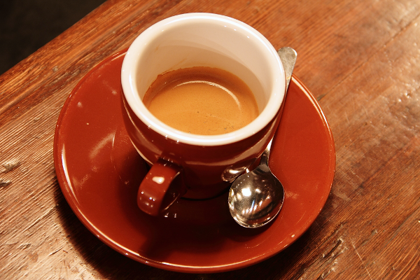

In [ ]:
candidate_sets = {
    "Different drinks": ["a cup of coffee", "a cup of tea", "a glass of orange juice"],
    "Overlapping descriptions": ["a cup of coffee", "a cup of espresso", "a cup of cappuccino", "a cup of tea"],
    "Coffee omitted": ["a cup of tea", "a glass of orange juice", "a glass of water"],
}

display(gallery_images[1].resize((420, 280)))

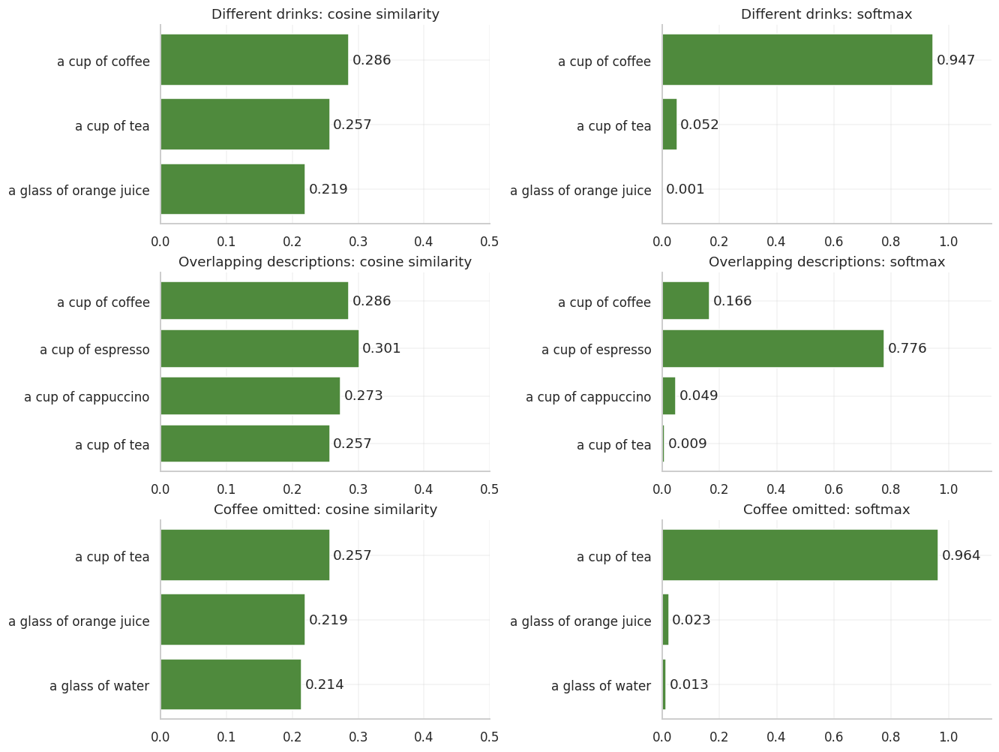

In [ ]:
candidate_tables = []
fig, axes = plt.subplots(3, 2, figsize=(12, 9), layout="constrained")

for row, (name, candidates) in enumerate(candidate_sets.items()):
    # cosine scores are computed independently for each image-description pair
    similarities = (gallery_features[1:2] @ encode_texts(candidates).T).squeeze(0)
    # softmax normalizes over the candidates in this list
    probabilities = (clip_scale * similarities).softmax(dim=-1)

    bars = axes[row, 0].barh(candidates, similarities.numpy(), color=COLOR)
    axes[row, 0].bar_label(bars, fmt="%.3f", padding=3)
    axes[row, 0].set(xlim=(0, 0.5), title=f"{name}: cosine similarity")
    axes[row, 0].invert_yaxis()

    bars = axes[row, 1].barh(candidates, probabilities.numpy(), color=COLOR)
    axes[row, 1].bar_label(bars, fmt="%.3f", padding=3)
    axes[row, 1].set(xlim=(0, 1.15), title=f"{name}: softmax")
    axes[row, 1].invert_yaxis()

    candidate_tables.append(pd.DataFrame({
        "Set": name, "Description": candidates,
        "Cosine": similarities.numpy(), "Softmax": probabilities.numpy(),
    }))
plt.show()

In [ ]:
candidate_results = pd.concat(candidate_tables, ignore_index=True)

# the tea description occurs in all three lists
tea_scores = candidate_results[candidate_results["Description"] == "a cup of tea"]
display(tea_scores.style.format({"Cosine": "{:.4f}", "Softmax": "{:.2%}"}))

,Set,Description,Cosine,Softmax
1,Different drinks,a cup of tea,0.2567,5.18%
6,Overlapping descriptions,a cup of tea,0.2567,0.91%
7,Coffee omitted,a cup of tea,0.2567,96.38%


Softmax divides the score among the available candidates. Removing coffee gives tea a high score even though the image still shows coffee.

### Image crops and CLIP preprocessing

CLIP ViT-B/32 resizes and center-crops its input to a square. A relevant object may become small or disappear at the edge. Lets compare the full scene with a manual object crop while keeping the descriptions fixed.

We will work with [Ultralytics example assets](https://github.com/ultralytics/assets/blob/main/im/bus.jpg).

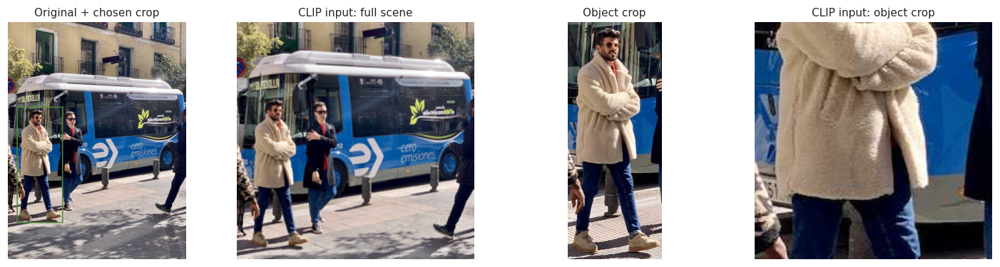

In [ ]:
SCENE_URL = 'https://raw.githubusercontent.com/ultralytics/assets/main/im/bus.jpg'
response = requests.get(SCENE_URL, timeout=30)
response.raise_for_status()
scene_image = Image.open(io.BytesIO(response.content)).convert("RGB")
crop_box = [40, 385, 250, 915]  # left, top, right, bottom in original pixels
scene_crop = scene_image.crop(crop_box)
scene_images = [scene_image, scene_crop]
scene_names = ["Full image", "Object crop"]
scene_captions = ['a blue bus on a city street', 'a person wearing a beige coat', 'the facade of an apartment building', 'a dog sitting on the road']

marked_scene = scene_image.copy()
ImageDraw.Draw(marked_scene).rectangle(crop_box, outline=COLOR, width=5)

# resize, center-crop and normalize both inputs
pixels = clip_processor(images=scene_images, return_tensors="pt")["pixel_values"]
mean = torch.tensor(clip_processor.image_processor.image_mean).view(1, 3, 1, 1)
std = torch.tensor(clip_processor.image_processor.image_std).view(1, 3, 1, 1)

# undo channel normalization and change chw to hwc for plotting
model_views = (pixels * std + mean).clamp(0, 1).permute(0, 2, 3, 1).numpy()
show_gallery([marked_scene, model_views[0], scene_crop, model_views[1]],
             ["Original + chosen crop", "CLIP input: full scene", "Object crop", "CLIP input: object crop"],
             ncols=4, size=3.3)

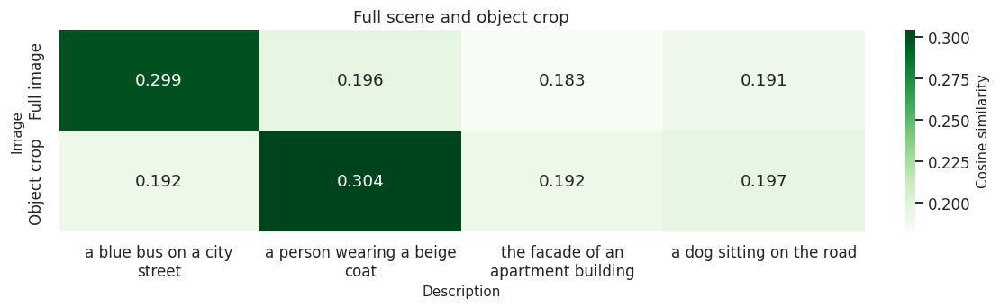

In [ ]:
scene_similarities = encode_images(scene_images) @ encode_texts(scene_captions).T
fig, ax = plt.subplots(figsize=(10, 3), layout="constrained")
sns.heatmap(scene_similarities.numpy(), annot=True, fmt=".3f", cmap=CMAP,
            xticklabels=[textwrap.fill(text, 25) for text in scene_captions],
            yticklabels=scene_names, cbar_kws={"label": "Cosine similarity"}, ax=ax)
ax.set(title="Full scene and object crop", xlabel="Description", ylabel="Image")
ax.tick_params(axis="x", rotation=0)
plt.show()

The crop enlarges the person and removes much of the surrounding scene.

### From images to sounds: CLAP

[CLAP](https://github.com/LAION-AI/CLAP) compares audio embeddings with text embeddings. We use six environmental sounds from [ESC-50](https://github.com/karolpiczak/ESC-50), one recording per selected category and compare class names with descriptions of audible events.

In [ ]:
from math import gcd

import soundfile as sf
from scipy.signal import resample_poly, spectrogram
from transformers import ClapModel, ClapProcessor

sound_examples = pd.DataFrame([
    ("1-100032-A-0.wav", "dog", "A dog is barking."),
    ("1-17367-A-10.wav", "rain", "Rain is falling steadily onto a surface."),
    ("1-172649-A-40.wav", "helicopter", "The blades of a helicopter are whirring."),
    ("1-104089-A-22.wav", "clapping", "People are clapping their hands."),
    ("1-100210-A-36.wav", "vacuum cleaner", "A vacuum cleaner is running."),
    ("1-13571-A-46.wav", "church bells", "Large church bells are ringing."),
], columns=["filename", "label", "description"])

audio_waveforms = []
original_rates = []

# clap expects mono audio sampled at 48 khz
audio_rate = 48000
esc_root = "https://raw.githubusercontent.com/karolpiczak/ESC-50/master/audio"
for filename in sound_examples.filename:
    response = requests.get(f"{esc_root}/{filename}", timeout=60)
    response.raise_for_status()
    waveform, original_rate = sf.read(io.BytesIO(response.content), dtype="float32")
    if waveform.ndim == 2:
        waveform = waveform.mean(axis=1)

    # resample the waveform, rather than changing only the sample-rate label
    factor = gcd(original_rate, audio_rate)
    waveform = resample_poly(waveform, audio_rate // factor, original_rate // factor)
    audio_waveforms.append(waveform.astype(np.float32))
    original_rates.append(original_rate)

print(f"Loaded {len(audio_waveforms)} clips, original sample rates: {set(original_rates)} Hz.")
print(f"Resampled to {audio_rate} Hz for CLAP, playback uses the same sample rate.")

Loaded 6 clips, original sample rates: {44100} Hz.
Resampled to 48000 Hz for CLAP, playback uses the same sample rate.


In [ ]:
display(sound_examples[["label", "description", "filename"]])

,label,description,filename
0,dog,A dog is barking.,1-100032-A-0.wav
1,rain,Rain is falling steadily onto a surface.,1-17367-A-10.wav
2,helicopter,The blades of a helicopter are whirring.,1-172649-A-40.wav
3,clapping,People are clapping their hands.,1-104089-A-22.wav
4,vacuum cleaner,A vacuum cleaner is running.,1-100210-A-36.wav
5,church bells,Large church bells are ringing.,1-13571-A-46.wav


In [ ]:
# labels come from esc-50

audio_cards = []
for label, waveform in zip(sound_examples.label, audio_waveforms):
    player = Audio(waveform, rate=audio_rate)._repr_html_()
    audio_cards.append(f"<div style='padding:10px'><b>{label}</b><br>{player}</div>")
display(HTML("<div style='display:flex;flex-wrap:wrap'>" + "".join(audio_cards) + "</div>"))

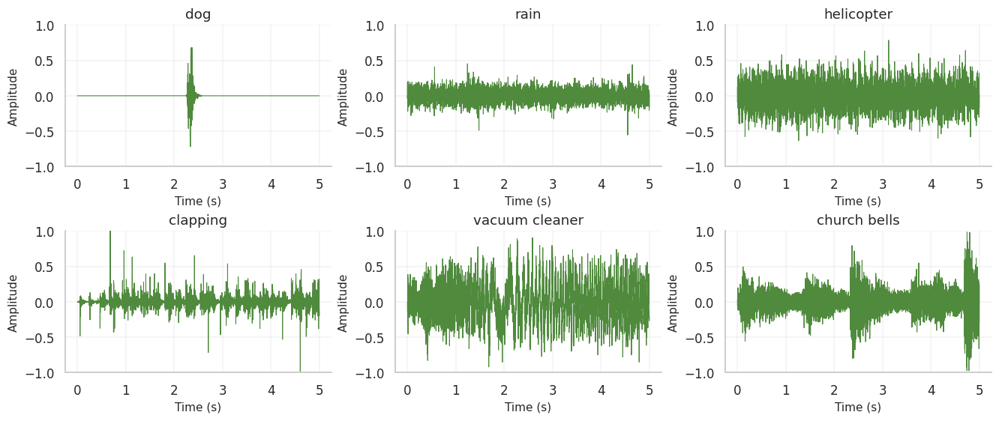

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5), layout="constrained")
for ax, label, waveform in zip(axes.flat, sound_examples.label, audio_waveforms):
    time_axis = np.arange(len(waveform)) / audio_rate
    # reduce plot density without changing the waveform sent to clap
    ax.plot(time_axis[::48], waveform[::48], color=COLOR, lw=0.7)
    ax.set(title=label, xlabel="Time (s)", ylabel="Amplitude", ylim=(-1, 1))
plt.show()

The waveforms show amplitude over time. Clapping and bell strikes produce repeated transients. Rain and a running vacuum produce more sustained sound.

In [ ]:
# free gpu memory before loading clap
clip_model = None
gc.collect()
torch.cuda.empty_cache()

clap_id = "laion/clap-htsat-unfused"
clap_processor = ClapProcessor.from_pretrained(clap_id)
clap_model = ClapModel.from_pretrained(clap_id).to(device).eval()
assert clap_processor.feature_extractor.sampling_rate == audio_rate

@torch.inference_mode()
def classify_sounds(prompts):
    # text and audio use different padding conventions
    text_inputs = clap_processor(text=prompts, padding=True, return_tensors="pt")
    audio_inputs = clap_processor(audio=audio_waveforms, sampling_rate=audio_rate,
                                  padding="repeatpad", return_tensors="pt")
    inputs = {key: value.to(device) for key, value in {**text_inputs, **audio_inputs}.items()}
    # logits_per_audio has shape [6 recordings, n_descriptions]
    return clap_model(**inputs).logits_per_audio.float().cpu()

audio_descriptions = sound_examples.description.tolist()
audio_logits = classify_sounds(audio_descriptions)
audio_scores = audio_logits.softmax(dim=-1)

preprocessor_config.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/615M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/614M [00:00<?, ?B/s]

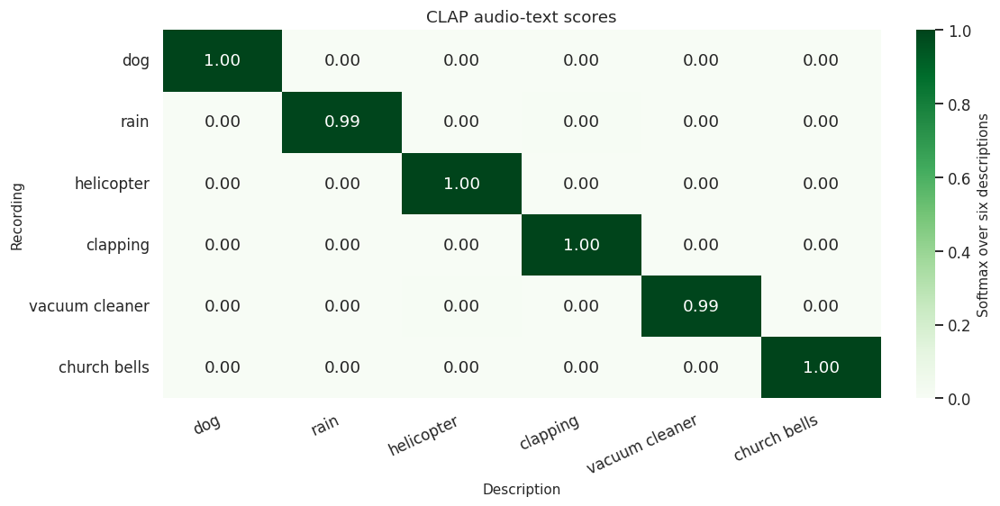

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
sns.heatmap(audio_scores.numpy(), annot=True, fmt=".2f", cmap=CMAP, vmin=0, vmax=1,
            xticklabels=sound_examples.label, yticklabels=sound_examples.label,
            cbar_kws={"label": "Softmax over six descriptions"}, ax=ax)
ax.set(xlabel="Description", ylabel="Recording", title="CLAP audio-text scores")
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
plt.show()

Both prompt sets classify all six recordings correctly.

#### More competing classes

We keep the same six recordings and their class names, then add the other 44 ESC-50 classes. The new list includes alternatives such as `engine` and `airplane`, which were absent from the first comparison.

In [ ]:
esc_revision = "33c8ce9eb2cf0b1c2f8bcf322eb349b6be34dbb6"
esc_metadata = pd.read_csv(
    f"https://raw.githubusercontent.com/karolpiczak/ESC-50/{esc_revision}/meta/esc50.csv"
)

# order class names by the dataset's numeric labels
esc_classes = esc_metadata[["target", "category"]].drop_duplicates().sort_values("target")
all_sound_labels = esc_classes["category"].str.replace("_", " ", regex=False).tolist()

# score the original six recordings against all 50 class names
expanded_audio_logits = classify_sounds(all_sound_labels)
expanded_audio_scores = expanded_audio_logits.softmax(dim=-1)

In [ ]:
candidate_comparison = audio_prompt_results[["Reference", "Class name"]].rename(
    columns={"Class name": "6 classes"}
)
expanded_predictions = expanded_audio_scores.argmax(dim=-1).tolist()
candidate_comparison["50 classes"] = [all_sound_labels[i] for i in expanded_predictions]
display(candidate_comparison)

,Reference,6 classes,50 classes
0,dog,dog,dog
1,rain,rain,rain
2,helicopter,helicopter,engine
3,clapping,clapping,clapping
4,vacuum cleaner,vacuum cleaner,vacuum cleaner
5,church bells,church bells,church bells


With six class names, CLAP gets all six recordings right. With 50 class names, it gets five right. The helicopter recording is now classified as `engine`, although its audio and the text `helicopter` have not changed.

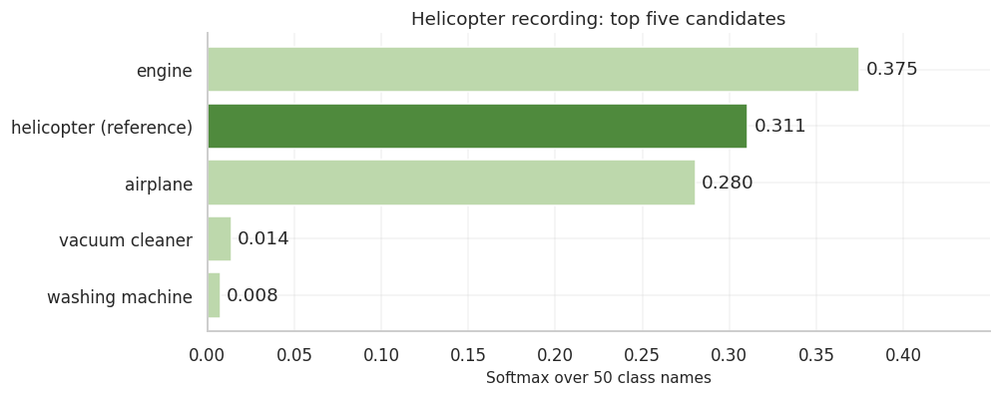

In [ ]:
helicopter_index = sound_examples.label.tolist().index("helicopter")
top_scores, top_indices = expanded_audio_scores[helicopter_index].topk(5)
top_labels = [all_sound_labels[i] for i in top_indices.tolist()]

colors = [COLOR if label == "helicopter" else LIGHT_COLOR for label in top_labels]
plot_labels = [label + " (reference)" if label == "helicopter" else label for label in top_labels]

fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
bars = ax.barh(plot_labels, top_scores.numpy(), color=colors)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set(xlabel="Softmax over 50 class names", title="Helicopter recording: top five candidates")
ax.invert_yaxis()
ax.margins(x=0.2)
plt.show()

CLAP ranks the broad description `engine` above the recording's dataset label. With the smaller candidate list, neither `engine` nor `airplane` was available.

#### The misclassified recording

This is the same helicopter recording used above. The waveform shows its changing amplitude, and the spectrogram shows how its energy is distributed over time and frequency.

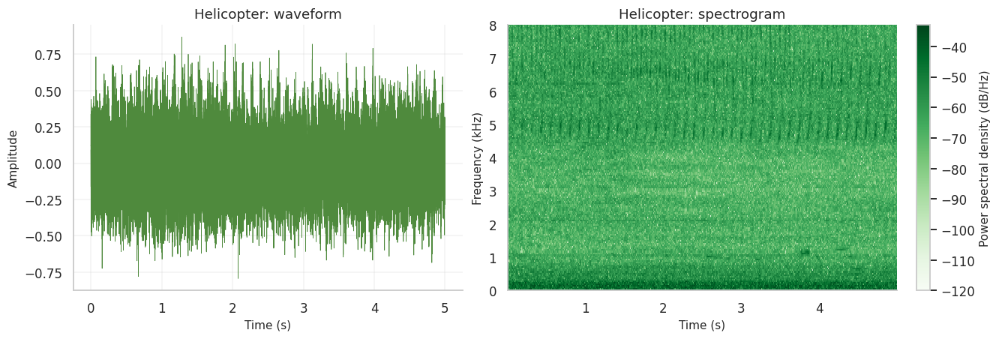

In [ ]:
sound_index = 2
waveform = audio_waveforms[sound_index]

# estimate frequency content in overlapping windows and convert power to db
frequencies, times, power = spectrogram(waveform, fs=audio_rate, nperseg=1024, noverlap=768)
power_db = 10 * np.log10(np.maximum(power, 1e-12))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(np.arange(len(waveform)) / audio_rate, waveform, color=COLOR, lw=0.5)
axes[0].set(title="Helicopter: waveform", xlabel="Time (s)", ylabel="Amplitude")
image = axes[1].pcolormesh(times, frequencies / 1000, power_db, shading="auto", cmap=CMAP)
axes[1].set(title="Helicopter: spectrogram", xlabel="Time (s)", ylabel="Frequency (kHz)", ylim=(0, 8))
fig.colorbar(image, ax=axes[1], label="Power spectral density (dB/Hz)")
plt.show()

In [ ]:
display(Audio(waveform, rate=audio_rate))

### From scoring descriptions to generating answers

CLIP ranks supplied descriptions. [Qwen3-VL-2B-Instruct](https://huggingface.co/Qwen/Qwen3-VL-2B-Instruct) generates text from an instruction and an image. We use the same scene and crop with two prompts: one requests a candidate number, the other a sentence describing objects and their spatial relationships. [Transformers documentation](https://huggingface.co/docs/transformers/v4.57.3/en/model_doc/qwen3_vl).

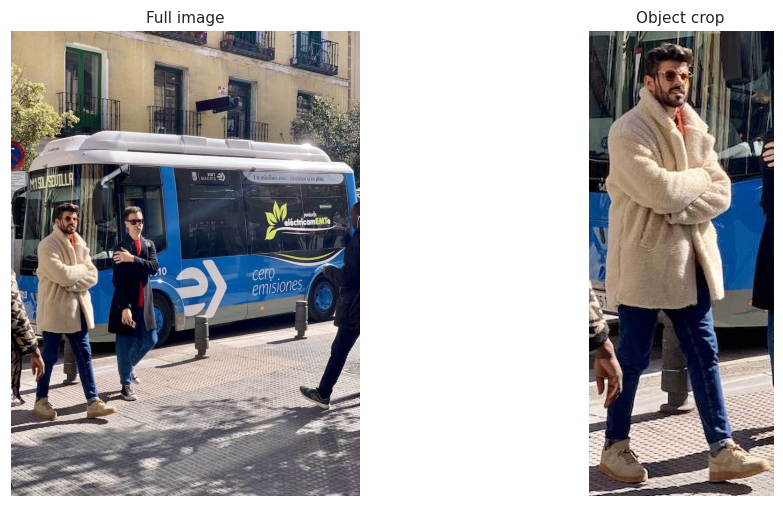

In [ ]:
show_gallery(scene_images, scene_names, ncols=2, size=4.5)

In [ ]:
# use exactly the same candidate descriptions as above
options = "\n".join(f"{i + 1}. {caption}" for i, caption in enumerate(scene_captions))
print(options)

1. a blue bus on a city street
2. a person wearing a beige coat
3. the facade of an apartment building
4. a dog sitting on the road


In [ ]:
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration

# release clap before loading qwen
clap_model = None
gc.collect()
torch.cuda.empty_cache()

qwen_id = "Qwen/Qwen3-VL-2B-Instruct"
# limit the number of visual tokens
qwen_processor = AutoProcessor.from_pretrained(
    qwen_id, min_pixels=128 * 32 * 32, max_pixels=384 * 32 * 32,
)
qwen_model = Qwen3VLForConditionalGeneration.from_pretrained(
    qwen_id, dtype=torch.float16, device_map={"": 0},
    attn_implementation="sdpa",
).eval()

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/4.26G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

In [ ]:
@torch.inference_mode()
def ask_image(image, question, max_new_tokens=80):
    messages = [{
        "role": "user",
        "content": [{"type": "image"}, {"type": "text", "text": question}],
    }]
    # apply the chat format, then preprocess the image and tokenize the prompt
    text = qwen_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = qwen_processor(text=[text], images=[image], return_tensors="pt").to(qwen_model.device)

    # use greedy decoding
    generated = qwen_model.generate(
        **inputs, max_new_tokens=max_new_tokens, do_sample=False,
        temperature=None, top_p=None, top_k=None,
    )

    # generate() returns prompt tokens followed by answer tokens
    answer_tokens = generated[:, inputs.input_ids.shape[1]:]
    return qwen_processor.batch_decode(answer_tokens, skip_special_tokens=True)[0].strip()

choice_question = (
    "Which description best matches this image? Choose exactly one option. "
    "Reply with the option number only.\n" + options
)

qwen_comparison = []

for i, (name, image) in enumerate(zip(scene_names, scene_images)):
    qwen_comparison.append({
        "Input": name,
        "CLIP choice": scene_captions[int(scene_similarities[i].argmax())],
        "Qwen raw choice": ask_image(image, choice_question, max_new_tokens=16),
        "Qwen open answer": ask_image(
            image, "Describe the main objects and their spatial relationships in one sentence."
        ),
    })

qwen_results = pd.DataFrame(qwen_comparison)

In [ ]:
display(qwen_results[["Input", "CLIP choice", "Qwen raw choice"]])

,Input,CLIP choice,Qwen raw choice
0,Full image,a blue bus on a city street,1
1,Object crop,a person wearing a beige coat,2


In [ ]:
with pd.option_context("display.max_colwidth", None):
    display(qwen_results[["Input", "Qwen open answer"]])

,Input,Qwen open answer
0,Full image,"A blue and white electric bus, labeled ""cero emisiones"" and ""electricamante,"" is parked on a city street with pedestrians walking nearby, including a man in a beige coat and another in a black jacket, with a yellow building and green trees in the background."
1,Object crop,"A man with a beard and sunglasses stands with his arms crossed, wearing a cream-colored, fluffy coat, blue jeans, and tan shoes, on a paved street next to a blue bus."


Qwen returns `1` for the full scene and `2` for the crop, correctly choosing the bus and the person. Both answers follow the requested number-only format.

The crop description identifies the beard, sunglasses and crossed arms. The full-scene description also captures the main objects, but transcribes **a word on the bus** as "electricamante", which does not match the lettering.


### Zero-shot inference with vLLM

[vLLM](https://docs.vllm.ai/en/v0.11.0/) schedules inference requests and manages the KV cache. We use the same Qwen checkpoint to process the image gallery, submitting requests one at a time and together.

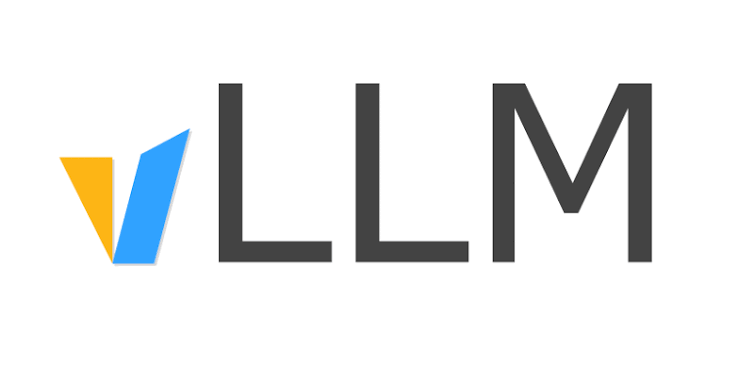

Both modes use the same images, prompts, precision, resolution and generation limits. Each mode runs once for warm-up, followed by three measured runs in alternating order. Timing includes image processing and generation. Model loading happens beforehand.

[vLLM paper](https://arxiv.org/abs/2309.06180), [Qwen-VL example](https://docs.vllm.ai/en/v0.11.0/examples/offline_inference/vision_language.html), [engine arguments](https://docs.vllm.ai/en/v0.11.0/configuration/engine_args.html).

In [ ]:
from time import perf_counter
from transformers import AutoProcessor

# start fresh worker processes after cuda initialization
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

N_REQUESTS = 8
vllm_images = (gallery_images + scene_images)[:N_REQUESTS]
vllm_names = (gallery_names + scene_names)[:N_REQUESTS]
vllm_candidates = gallery_captions + scene_captions[:2]
options = "\n".join(f"{i + 1}. {caption}" for i, caption in enumerate(vllm_candidates))
vllm_question = (
    "Choose the description that best matches this image. "
    "Start with its option number, then give one short sentence of visible evidence.\n" + options
)

# release the transformers models
qwen_model = None
gc.collect()
torch.cuda.empty_cache()

vllm_processor = AutoProcessor.from_pretrained(qwen_id)
messages = [{"role": "user", "content": [
    {"type": "image"}, {"type": "text", "text": vllm_question},
]}]

prompt = vllm_processor.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True,
)

# pass each pil image with its text prompt
vllm_requests = [{"prompt": prompt, "multi_modal_data": {"image": image}}
                 for image in vllm_images]

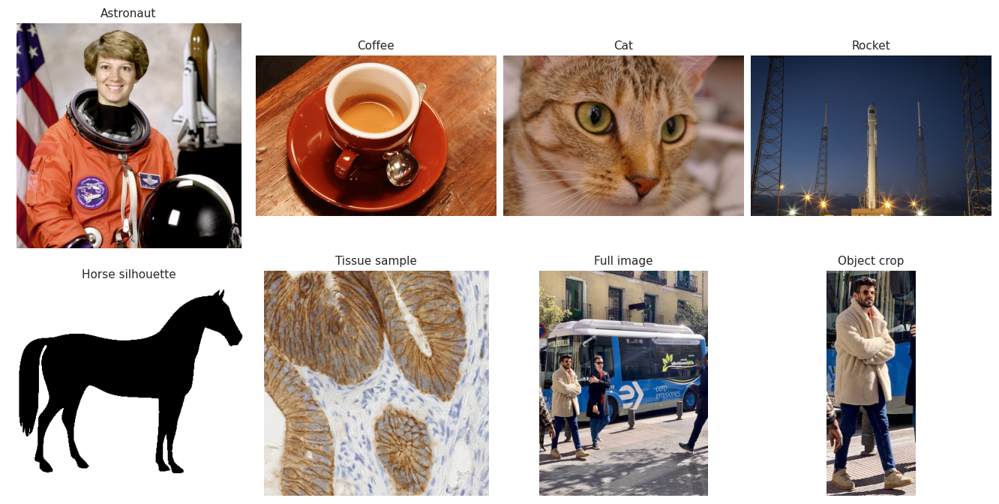

In [ ]:
show_gallery(vllm_images, vllm_names, ncols=4, size=3)

In [ ]:
print(vllm_question)

Choose the description that best matches this image. Start with its option number, then give one short sentence of visible evidence.
1. a portrait of an astronaut in a spacesuit
2. a cup of coffee on a wooden table
3. a close-up photo of a tabby cat
4. a rocket on a launch pad
5. a black and white silhouette of a horse
6. a microscope image of stained biological tissue
7. a blue bus on a city street
8. a person wearing a beige coat


#### Inference settings

`max_num_seqs` limits concurrent requests. `max_model_len` limits the total input and output length. The GPU memory budget includes model weights and the KV cache. One engine serves both modes of the comparison.

In [ ]:
from vllm import LLM, SamplingParams

vllm_model = LLM(
    model=qwen_id,
    dtype="float16",
    max_model_len=2048,
    max_num_seqs=8,
    max_num_batched_tokens=4096,
    gpu_memory_utilization=0.65,

    # disable cuda graphs and cached input reuse
    enforce_eager=True,
    enable_prefix_caching=False,
    mm_processor_cache_gb=0,
    mm_processor_kwargs={"min_pixels": 128 * 32 * 32, "max_pixels": 384 * 32 * 32},
    limit_mm_per_prompt={"image": 1, "video": 0},
    seed=42,
)

sampling = SamplingParams(temperature=0, max_tokens=64, seed=42)

INFO 11-14 07:22:04 [__init__.py:216] Automatically detected platform cuda.
INFO 11-14 07:22:07 [utils.py:233] non-default args: {'dtype': 'float16', 'seed': 42, 'max_model_len': 2048, 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.65, 'max_num_batched_tokens': 4096, 'max_num_seqs': 8, 'disable_log_stats': True, 'enforce_eager': True, 'limit_mm_per_prompt': {'image': 1, 'video': 0}, 'mm_processor_kwargs': {'min_pixels': 131072, 'max_pixels': 393216}, 'mm_processor_cache_gb': 0, 'model': 'Qwen/Qwen3-VL-2B-Instruct'}
INFO 11-14 07:22:27 [model.py:547] Resolved architecture: Qwen3VLForConditionalGeneration


`torch_dtype` is deprecated! Use `dtype` instead!


WARNING 11-14 07:22:27 [model.py:1733] Casting torch.bfloat16 to torch.float16.
INFO 11-14 07:22:27 [model.py:1510] Using max model len 2048
INFO 11-14 07:22:27 [scheduler.py:205] Chunked prefill is enabled with max_num_batched_tokens=4096.
INFO 11-14 07:22:27 [__init__.py:381] Cudagraph is disabled under eager mode
INFO 11-14 07:23:07 [llm.py:306] Supported_tasks: ['generate']


In [ ]:
schedules = ["One at a time", f"Batch of {len(vllm_requests)}"]

# warm up both modes
for request in vllm_requests:
    vllm_model.generate([request], sampling, use_tqdm=False)
vllm_model.generate(vllm_requests, sampling, use_tqdm=False)

measurements = []
vllm_answers = {}
for repeat in range(3):

    # alternate order to reduce the effect of always measuring one mode first
    order = schedules if repeat % 2 == 0 else schedules[::-1]
    for schedule in order:
        start = perf_counter()
        if schedule == "One at a time":
            outputs = []
            for request in vllm_requests:
                outputs.extend(vllm_model.generate([request], sampling, use_tqdm=False))
        else:
            outputs = vllm_model.generate(vllm_requests, sampling, use_tqdm=False)
        elapsed = perf_counter() - start

        # count generated tokens, excluding the input prompt
        token_count = sum(len(output.outputs[0].token_ids) for output in outputs)
        measurements.append({
            "Schedule": schedule,
            "Repeat": repeat + 1,
            "Total time (s)": elapsed,
            "Images/s": len(vllm_requests) / elapsed,
            "New tokens": token_count,
            "Output tokens/s": token_count / elapsed,
        })
        vllm_answers[schedule] = [output.outputs[0].text.strip() for output in outputs]

measurements = pd.DataFrame(measurements)
vllm_summary = measurements.groupby("Schedule", sort=False).median(numeric_only=True)
vllm_summary = vllm_summary.drop(columns="Repeat")

In [ ]:
display(vllm_summary.round(2))

,Total time (s),Images/s,New tokens,Output tokens/s
Schedule,,,,
One at a time,4.75,1.68,168.0,35.37
Batch of 8,1.34,5.98,159.0,118.84


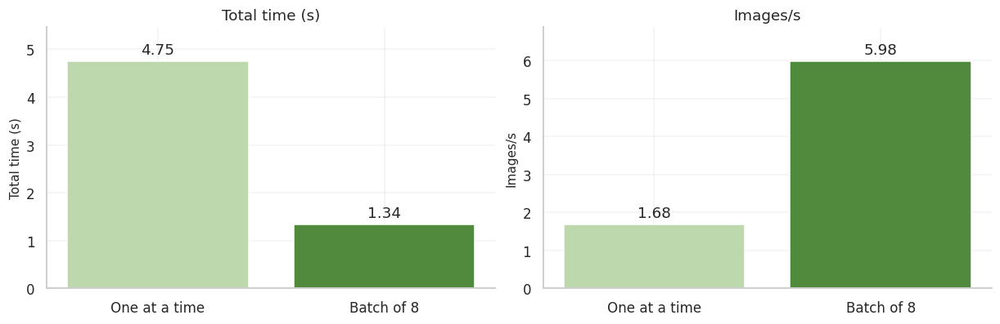

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for ax, metric in zip(axes, ["Total time (s)", "Images/s"]):
    bars = ax.bar(vllm_summary.index, vllm_summary[metric], color=[LIGHT_COLOR, COLOR])
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set(ylabel=metric, title=metric)
    ax.margins(y=0.15)
plt.show()

In [ ]:
vllm_answer_table = pd.DataFrame(vllm_answers, index=vllm_names)
vllm_answer_table.index.name = "Image"
with pd.option_context("display.max_colwidth", None):
    display(vllm_answer_table)

,One at a time,Batch of 8
Image,,
Astronaut,1. a portrait of an astronaut in a spacesuit,1. a portrait of an astronaut in a spacesuit
Coffee,2. a cup of coffee on a wooden table\n\nThe image shows a cup of coffee with a spoon and saucer on a wooden table.,2. a cup of coffee on a wooden table\n\nThe image shows a cup of coffee with a spoon and saucer on a wooden table.
Cat,"3. a close-up photo of a tabby cat\nThe image shows a close-up of a cat's face, with visible features such as green eyes, a striped coat, and whiskers, which are characteristic of a tabby cat.","3. a close-up photo of a tabby cat\nThe image shows a close-up of a cat's face, with visible features such as green eyes, a striped coat, and whiskers."
Rocket,4. a rocket on a launch pad,4. a rocket on a launch pad
Horse silhouette,5. a black and white silhouette of a horse,5. a black and white silhouette of a horse
Tissue sample,"6. a microscope image of stained biological tissue\n\nThe image shows a detailed view of tissue with cells stained in different colors, which is characteristic of a histological or microscopic examination.","6. a microscope image of stained biological tissue\n\nThe image shows a detailed view of tissue with cells stained in different colors, which is characteristic of a histological or microscopic examination."
Full image,7. a blue bus on a city street,7. a blue bus on a city street
Object crop,8. a person wearing a beige coat,8. a person wearing a beige coat


Both modes choose all eight classes correctly. Only the coffee, cat and tissue answers include the requested explanation. The other five return just the selected option.


### Takeaways

- CLIP and CLAP can classify inputs by comparing them with candidate text descriptions.
- Prompt wording and ensembling can change predictions without changing model weights.
- Softmax scores depend on the candidate list. A high score does not guarantee that the correct class is among the candidates.
- Image preprocessing and cropping change which details and context the model sees.
- Generative vision-language models can describe images and follow instructions, but can make factual errors or miss parts of a request.
- Batching can improve throughput. Response length and answer quality matter when comparing inference speed.
